In [264]:
import os
import sys
import re
sys.path.insert(0, os.getcwd() + "/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, os.getcwd() + "/fit") #add a pathway to the fit functions #not sure about how to use folder dependency, to change

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
import sobol_seq
from numpy.linalg import norm
from sklearn.decomposition import PCA

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


#change the model parameters of the model if needed

# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/model_data/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

# Directory containing cell fate data
from pathlib import Path

DATADIR = Path('../Data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
#SAVE_DIR = 'D:\\stoch_runs_230713\\'
SAVE_DIR = Path(Path.home(),'data')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()


Unnamed: 0


In [2]:
import pandas as pd
import numpy as np
import umap
import joblib
from pathlib import Path
import os
import glob

In [572]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'stoch_sim*orig.csv')
filenames = glob.glob(file_location)
filenames = sorted(filenames)
filenames_sp = [filenames[2], filenames[3], filenames[0], filenames[1], filenames[4], filenames[5]]
filenames

['C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_int_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_soft_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff060_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff072_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\stoch_sim_stiff_erl_param_orig.csv']

In [4]:
file_location = os.path.join('C:\\Users\\olesk\\ECM_mod_output\\', 'ODE_sim*orig.csv')
filenames_ode = glob.glob(file_location)
filenames_ode = sorted(filenames_ode)
filenames_sp_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0], filenames_ode[1], filenames_ode[4], filenames_ode[5]]
filenames_sp_ode

['C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_soft_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_int_erl_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_DMSO_param_orig.csv',
 'C:\\Users\\olesk\\ECM_mod_output\\ODE_sim_stiff_erl_param_orig.csv']

In [5]:
#The filenames to make the reducer umap object from
"""
filenames = ['erl_4-9_1_1.txt', 'erl_4-9_2_1.txt', 'erl_4-9_3_1.txt',
             'dmso_4-9_1_1.txt', 'dmso_4-9_2_1.txt', 'dmso_4-9_3_1.txt']
#Important params to set the window size and step time distance
init_dt = 0.01                #initial dt from the raw model output
dt = 0.1                      #dt for umap window
window = 4                    #window size in hours
time_step = 1                 #time step between windows

#umap params
neighbs = 100
min_d = 0.02
"""
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.05

#reducer save name
r_name = f'reducer_07_25_{init_dt}_{dt}_{window}_{time_step}.sav'

In [6]:
def plot_phase(filenames, filenames_ode):
    sf = 1
    fig = plt.figure()
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp_ode[prot_tmp_ode<0] = 0 #from old extrap. method, don't think I need this 
        
        plt.subplot(3,2,sf)
        
        plt.plot(prot_tmp['cycE'], prot_tmp['cdc20'], lw=0.25, alpha=0.75, c='gray')
        plt.plot(prot_tmp_ode.iloc[-10000:,11], prot_tmp_ode.iloc[-10000:,17], lw=1, alpha=1, c='black')
        
        plt.xlim(0,1)
        plt.ylim(0,1)

        ax = plt.gca()
        if (sf % 2) == 0:
            ax.yaxis.set_tick_params(labelleft=False)
        if sf<5:
            ax.xaxis.set_tick_params(labelleft=False)
        
        sf += 1
        
    # Set common labels
    fig.text(0.5, 0.04, 'cyclin E', ha='center', va='center')
    fig.text(0.06, 0.5, 'cdc20', ha='center', va='center', rotation='vertical')
    

In [7]:
def plot_phase_norm(filenames, filenames_ode, max_prots, min_prots):
    sf = 1
    fig = plt.figure()
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp_ode[prot_tmp_ode<0] = 0 #from old extrap. method, don't think I need this 
        
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
        
        plt.subplot(3,2,sf)
        
        plt.plot(prot_tmp['cycE'], prot_tmp['cdc20'], lw=0.25, alpha=0.75, c='gray')
        plt.plot(prot_tmp_ode.iloc[-10000:,11], prot_tmp_ode.iloc[-10000:,17], lw=1, alpha=1, c='black')
        
        plt.xlim(0,1)
        plt.ylim(0,1)

        ax = plt.gca()
        if (sf % 2) == 0:
            ax.yaxis.set_tick_params(labelleft=False)
        if sf<5:
            ax.xaxis.set_tick_params(labelleft=False)
        
        sf += 1
        
    # Set common labels
    fig.text(0.5, 0.04, 'cyclin E', ha='center', va='center')
    fig.text(0.06, 0.5, 'cdc20', ha='center', va='center', rotation='vertical')
    
    

In [8]:
def load_norm_data(filenames, filenames_ode, time_all, init_dt, dt, window, time_step, plot_phase):
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
    
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(SAVE_DIR + f"phaseplot_{num}.png", bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(SAVE_DIR + f"phaseplot_norm_{num}.png", bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [9]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [10]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_sp, filenames_sp_ode, time_tmp2, init_dt, dt, window, time_step, plot_phase)

In [11]:
all_prot_tmp.shape

(239958, 720)

In [12]:
reducer = joblib.load('C:\\Users\\olesk\\data\\reducer_07_25_0.1_0.1_4_0.5.sav')

In [13]:
win_len = int(window/dt)

In [14]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [15]:
# choose number of components and define pca
pca = PCA(n_components = 2)

# use the pca on the data (without the time column)
principalComponents = pca.fit_transform(all_prot_tmp)

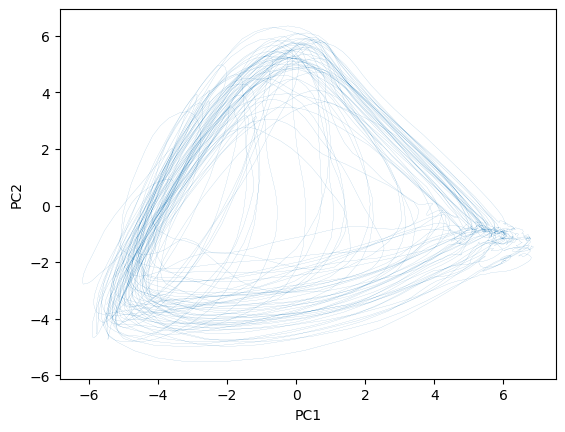

In [16]:
fig = plt.plot(principalComponents[:5000, 0], principalComponents[:5000, 1], lw=0.1, alpha=0.7)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

In [568]:
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = (len(all_prot_tmp_ode)/6/8)*7
w_len = len(all_prot_tmp_ode)/6
sp = 1
for n in range(6):
    tmp = all_prot_tmp_ode[int(n*w_len+ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [570]:
w_len

39993.0

In [18]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

In [19]:
all_prot_tmp_ode_ab.shape

(30000, 720)

Text(0.06, 0.77, 'Soft')

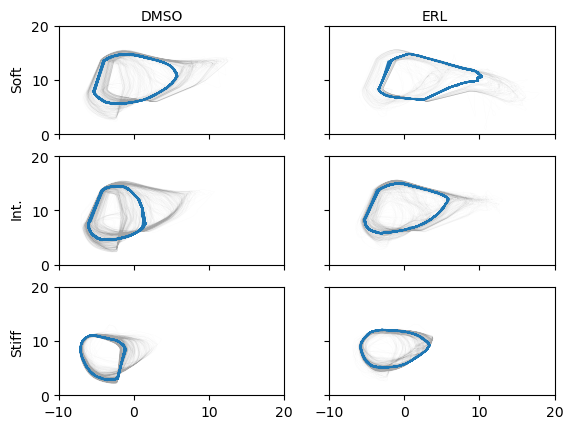

In [20]:
fig = plt.figure()
n1 = 1
for n in range(6):
    plt.subplot(3,2,n1)
    trk_len = int(len(embedding_all_prot)/6)
    trk_len_ode = int(len(embedding_all_prot_ode)/6)
    plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-10,20)
    plt.ylim(0, 20)

    ax = plt.gca()
    if (n1 % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<5:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

# Set common labels
fig.text(0.287, 0.9, 'DMSO', ha='center', va='center')
fig.text(0.713, 0.9, 'ERL', ha='center', va='center')
fig.text(0.06, 0.22, 'Stiff', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.5, 'Int.', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.77, 'Soft', ha='center', va='center', rotation='vertical')
# plt.savefig(SAVE_DIR + f"UMAP_neighbs{neighbs}_window{window}_tstep{time_step}_ORIG.png", bbox_inches='tight')

In [23]:
principalComponents = pca.fit_transform(all_prot_tmp)
principalComponents_ode = pca.transform(all_prot_tmp_ode_ab)

Text(0.06, 0.77, 'Soft')

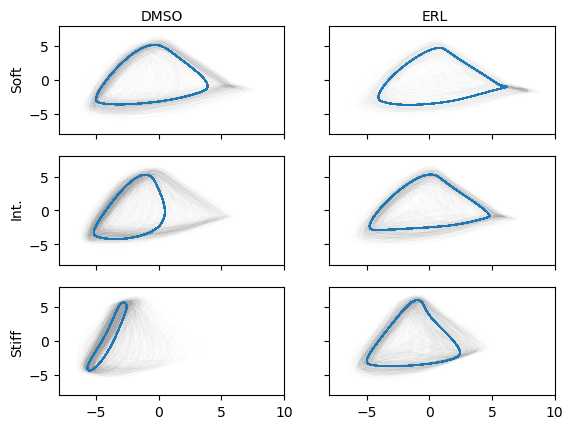

In [24]:
fig = plt.figure()
n1 = 1
for n in range(6):
    plt.subplot(3,2,n1)
    trk_len = int(len(principalComponents)/6)
    trk_len_ode = int(len(principalComponents_ode)/6)
    plt.plot(principalComponents[n*trk_len:n1*trk_len,0], principalComponents[n*trk_len:n1*trk_len,1], lw=0.01, alpha=0.7, c='gray')
    plt.plot(principalComponents_ode[n*trk_len_ode:n1*trk_len_ode,0], principalComponents_ode[n*trk_len_ode:n1*trk_len_ode,1], lw=1, alpha=1)

    plt.xlim(-8,10)
    plt.ylim(-8,8)

    ax = plt.gca()
    if (n1 % 2) == 0:
        ax.yaxis.set_tick_params(labelleft=False)
    if n1<5:
        ax.xaxis.set_tick_params(labelleft=False)
    n1 += 1

# Set common labels
fig.text(0.287, 0.9, 'DMSO', ha='center', va='center')
fig.text(0.713, 0.9, 'ERL', ha='center', va='center')
fig.text(0.06, 0.22, 'Stiff', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.5, 'Int.', ha='center', va='center', rotation='vertical')
fig.text(0.06, 0.77, 'Soft', ha='center', va='center', rotation='vertical')
# plt.savefig(SAVE_DIR + f"UMAP_neighbs{neighbs}_window{window}_tstep{time_step}_ORIG.png", bbox_inches='tight')

### Restructure protein activity levels for distance comparisons

In [25]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_soft_prot_df = pd.DataFrame(all_prot_tmp[1*trk_len:2*trk_len,:])
erl_soft_time_df = pd.DataFrame(all_time_tmp[1*trk_len:2*trk_len,:])
erl_soft_emb_df = pd.DataFrame(embedding_all_prot[1*trk_len:2*trk_len,:])
erl_soft_pca_df = pd.DataFrame(principalComponents[1*trk_len:2*trk_len,:])

dmso_soft_prot_df = pd.DataFrame(all_prot_tmp[0*trk_len:1*trk_len,:])
dmso_soft_time_df = pd.DataFrame(all_time_tmp[0*trk_len:1*trk_len,:])
dmso_soft_emb_df = pd.DataFrame(embedding_all_prot[0*trk_len:1*trk_len,:])
dmso_soft_pca_df = pd.DataFrame(principalComponents[0*trk_len:1*trk_len,:])

In [26]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_int_prot_df = pd.DataFrame(all_prot_tmp[3*trk_len:4*trk_len,:])
erl_int_time_df = pd.DataFrame(all_time_tmp[3*trk_len:4*trk_len,:])
erl_int_emb_df = pd.DataFrame(embedding_all_prot[3*trk_len:4*trk_len,:])
erl_int_pca_df = pd.DataFrame(principalComponents[3*trk_len:4*trk_len,:])

dmso_int_prot_df = pd.DataFrame(all_prot_tmp[2*trk_len:3*trk_len,:])
dmso_int_time_df = pd.DataFrame(all_time_tmp[2*trk_len:3*trk_len,:])
dmso_int_emb_df = pd.DataFrame(embedding_all_prot[2*trk_len:3*trk_len,:])
dmso_int_pca_df = pd.DataFrame(principalComponents[2*trk_len:3*trk_len,:])

In [27]:
trk_len = int(len(all_prot_tmp)/6)
y_label_list = ['Skp2', 'p21', 'pp21', 'Cdh1', 'Myc', 'CycD', 'CycDp21', 'Rb', 'pRb', 'E2F', 'RbE2F',
                'CycE', 'CycEp21', 'CycA', 'CycAp21', 'CycB', 'CycBp21', 'Cdc20']
erl_stiff_prot_df = pd.DataFrame(all_prot_tmp[5*trk_len:6*trk_len,:])
erl_stiff_time_df = pd.DataFrame(all_time_tmp[5*trk_len:6*trk_len,:])
erl_stiff_emb_df = pd.DataFrame(embedding_all_prot[5*trk_len:6*trk_len,:])
erl_stiff_pca_df = pd.DataFrame(principalComponents[5*trk_len:6*trk_len,:])

dmso_stiff_prot_df = pd.DataFrame(all_prot_tmp[4*trk_len:5*trk_len,:])
dmso_stiff_time_df = pd.DataFrame(all_time_tmp[4*trk_len:5*trk_len,:])
dmso_stiff_emb_df = pd.DataFrame(embedding_all_prot[4*trk_len:5*trk_len,:])
dmso_stiff_pca_df = pd.DataFrame(principalComponents[4*trk_len:5*trk_len,:])

In [28]:
def restructProt(protDF, embedDF, timeDF):
    peaks_E, _ = find_peaks(protDF.iloc[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(protDF.iloc[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    mit_win = pd.DataFrame()
    time_win = pd.DataFrame()
    umap_win = pd.DataFrame()
    num = 1
    
    for n in range(2,len(peaks_cdc)-3):   #make sure we have divisions at ends 
        tmp_mit = peaks_cdc[n]
        tmp_mit2 = peaks_cdc[n+1]
        tmp_mit3 = peaks_cdc[n+2]
        tmp_mit4 = peaks_cdc[n+3]
        
        tmp_g1_s = peaks_E[(tmp_mit < peaks_E) & (peaks_E < tmp_mit2)]
        tmp_g1_s_2 = peaks_E[(tmp_mit2 < peaks_E) & (peaks_E < tmp_mit3)]
        tmp_g1_s_3 = peaks_E[(tmp_mit3 < peaks_E) & (peaks_E < tmp_mit4)]    
             
        if (np.size(tmp_g1_s) > 0) & (np.size(tmp_g1_s_2)>0) & (np.size(tmp_g1_s_3)>0):
            ordered = [tmp_mit, tmp_g1_s[0], tmp_mit2, tmp_g1_s_2[0], tmp_mit3, tmp_g1_s_3[0], tmp_mit4]
            g1_len_tmp = np.array(timeDF.iloc[ordered[3],0]) - np.array(timeDF.iloc[[ordered[2]],0])
            tmp_prot = protDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_umap = embedDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp_time = timeDF.iloc[int(ordered[1]):int(ordered[4]),:]
            tmp = [g1_len_tmp]*len(tmp_time)
            tmp_g1s = [int(ordered[1])]*len(tmp_time)
            tmp_mit = [int(ordered[2])]*len(tmp_time)
            tmp_g1s2 = [int(ordered[3])]*len(tmp_time)
            tmp_mit2 = [int(ordered[4])]*len(tmp_time)
            
            tmp_time.insert(0, 'mit2', tmp_mit2)
            tmp_time.insert(0, 'G1-S_2', tmp_g1s2)
            tmp_time.insert(0, 'mit', tmp_mit)
            tmp_time.insert(0, 'G1-S', tmp_g1s)
            tmp_time.insert(0, 'G1_len', tmp)
            tmp_time.insert(0, 'div', [num]*len(tmp_time))
            num += 1
            
            mit_win = pd.concat([mit_win,tmp_prot],ignore_index=True)
            time_win = pd.concat([time_win, tmp_time], ignore_index=True)
            umap_win = pd.concat([umap_win, tmp_umap], ignore_index=True)
            
    return mit_win, time_win, umap_win

In [29]:
from scipy.signal import find_peaks

In [30]:
mit_win_erl_soft, time_win_erl_soft, umap_win_erl_soft = restructProt(erl_soft_prot_df, erl_soft_emb_df, erl_soft_time_df)
mit_win_erl_soft, time_win_erl_soft, pca_win_erl_soft = restructProt(erl_soft_prot_df, erl_soft_pca_df, erl_soft_time_df)

mit_win_dmso_soft, time_win_dmso_soft, umap_win_dmso_soft = restructProt(dmso_soft_prot_df, dmso_soft_emb_df, dmso_soft_time_df)
mit_win_dmso_soft, time_win_dmso_soft, pca_win_dmso_soft = restructProt(dmso_soft_prot_df, dmso_soft_pca_df, dmso_soft_time_df)


In [31]:
mit_win_erl_int, time_win_erl_int, umap_win_erl_int = restructProt(erl_int_prot_df, erl_int_emb_df, erl_int_time_df)
mit_win_erl_int, time_win_erl_int, pca_win_erl_int = restructProt(erl_int_prot_df, erl_int_pca_df, erl_int_time_df)

mit_win_dmso_int, time_win_dmso_int, umap_win_dmso_int = restructProt(dmso_int_prot_df, dmso_int_emb_df, dmso_int_time_df)
mit_win_dmso_int, time_win_dmso_int, pca_win_dmso_int = restructProt(dmso_int_prot_df, dmso_int_pca_df, dmso_int_time_df)

In [32]:
mit_win_erl_stiff, time_win_erl_stiff, umap_win_erl_stiff = restructProt(erl_stiff_prot_df, erl_stiff_emb_df, erl_stiff_time_df)
mit_win_erl_stiff, time_win_erl_stiff, pca_win_erl_stiff = restructProt(erl_stiff_prot_df, erl_stiff_pca_df, erl_stiff_time_df)

mit_win_dmso_stiff, time_win_dmso_stiff, umap_win_dmso_stiff = restructProt(dmso_stiff_prot_df, dmso_stiff_emb_df, dmso_stiff_time_df)
mit_win_dmso_stiff, time_win_dmso_stiff, pca_win_dmso_stiff = restructProt(dmso_stiff_prot_df, dmso_stiff_pca_df, dmso_stiff_time_df)


Text(0.5, 1.0, 'Cdc20')

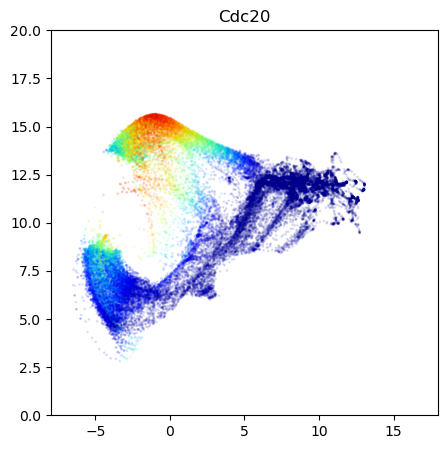

In [33]:
xmin, xmax = -8, 18
ymin, ymax = 0, 20
n=17

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_int[0],umap_win_erl_int[1],c=mit_win_erl_int[int((win_len*n+win_len/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

Text(0.5, 1.0, 'Cdc20')

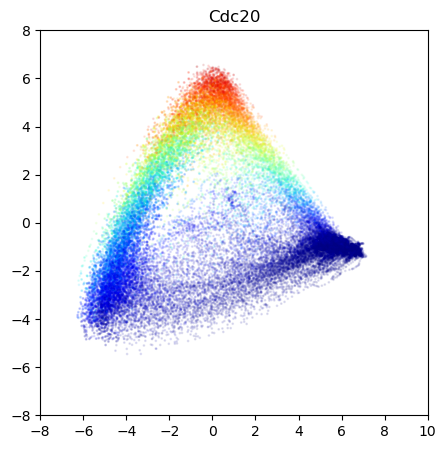

In [47]:
xmin, xmax = -8, 10
ymin, ymax = -8, 8
n=17

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(pca_win_erl_int[0],pca_win_erl_int[1],c=mit_win_erl_int[int((win_len*n+win_len/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

Text(0.5, 1.0, 'Rb')

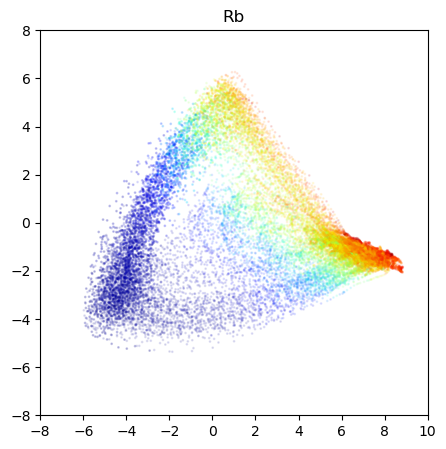

In [46]:
xmin, xmax = -8, 10
ymin, ymax = -8, 8
n=7

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(pca_win_erl_soft[0],pca_win_erl_soft[1],c=mit_win_erl_soft[int((win_len*n+win_len/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

Text(0.5, 1.0, 'Cdc20')

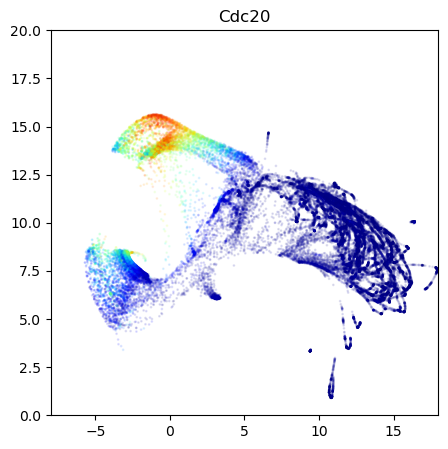

In [126]:
xmin, xmax = -8, 18
ymin, ymax = 0, 20
n=17

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_soft[0],umap_win_erl_soft[1],c=mit_win_erl_soft[int((win_len*n+win_len/2)-1)],s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 1)
plt.title(y_label_list[n])

In [25]:
def splitG1(timewinDF, protDF, t_before_div):
    # t_before_div - time in hours (0.5 hour increments)
    t_step = 0.5
    short_len = 35
    long_len = 30
    
    divDF = pd.DataFrame()
    all_imts = []
    
    for n in timewinDF['div'].unique():
        tmpDF = timewinDF.loc[timewinDF['div'] == n]
        
        if tmpDF.iloc[0,1][0] <= short_len:
            tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]-int(t_before_div/t_step),:])
            tmp = np.append(tmp, int(0))
            tmp = tmp.reshape(-1,len(tmp))
            indDF = pd.DataFrame(tmp)
            divDF = pd.concat([divDF,indDF],ignore_index=True)
#         elif (tmpDF.iloc[0,1][0] > short_len) & (tmpDF.iloc[0,1][0] <= long_len):
#             tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]-int(t_before_div/t_step),:])
#             tmp = np.append(tmp, int(1))
#             tmp = tmp.reshape(-1,len(tmp))
#             indDF = pd.DataFrame(tmp)
#             divDF = pd.concat([divDF,indDF],ignore_index=True)
        else:
            tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]-int(t_before_div/t_step),:])
            tmp = np.append(tmp, int(1))
            tmp = tmp.reshape(-1,len(tmp))
            indDF = pd.DataFrame(tmp)
            divDF = pd.concat([divDF,indDF],ignore_index=True)
            
        all_imts.append(tmpDF.iloc[0,1][0])
    return divDF, all_imts

In [26]:
dataset, imts_erl_int = splitG1(time_win_erl_int, erl_int_prot_df, 0)

(array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.00451467, 0.00902935, 0.01354402, 0.01128668, 0.02257336,
        0.02031603, 0.01354402, 0.04063205, 0.0248307 , 0.03160271,
        0.04740406, 0.03160271, 0.0248307 , 0.02934537, 0.04063205,
        0.01805869, 0.03160271, 0.0248307 , 0.02934537, 0.03160271,
        0.04063205, 0.03837472, 0.0248307 , 0.0248307 , 0.01805869,
        0.02257336, 0.01580135, 0.01354402, 0.01805869, 0.01354402,
        0.02031603, 0.01128668, 0.01354402, 0.01580135, 0.00225734,
        0.00451467, 0.00677201, 0.00225734, 0.01805869, 0.00902935,
        0.00902935, 0.00902935, 0.00677201, 0.        , 0.00451467,
        0.00225734, 0.01128668, 0.01128668, 0.01128668, 0.01128668,
        0.00225734, 0.00677201, 0.00902935, 0.00225734, 0.00451467,
        0.00677201, 0.00451467, 0.00677201, 0.00225734, 0.        ,
        0.00225734, 0.        , 0.        , 0.00225734, 0.00225734,
        0.00225734, 0.        , 0.00225734, 0.  

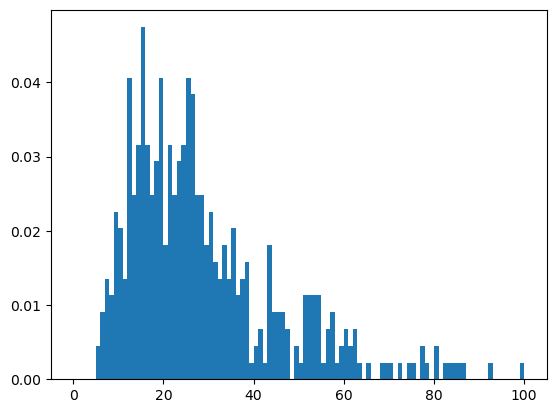

In [28]:
fig = plt.figure()
plt.hist(imts_erl_int, bins=np.arange(0,101,1), density=True)

In [242]:
def calc_dist(timewinDF, protDF, umapDF):
    # t_before_div - time in hours (0.5 hour increments)
    
    distDF = pd.DataFrame(columns=['Proj_Dist', 'Euc_Dist', 'IMT'])
    
    for n in timewinDF['div'].unique():
        tmpDF = timewinDF.loc[timewinDF['div'] == n]
        tmp = np.array(protDF.iloc[tmpDF.iloc[0,3]:tmpDF.iloc[0,5],:])
        tmp_umap = np.array(umapDF.iloc[tmpDF.index[0]:tmpDF.index[-1],:])
        
        tmp_r = [tmp[:,int((win_len*prot+win_len/2)-1)] for prot in range(18)]
        
        dist = 0        
        for ii in range(len(tmp_umap)-1):
            diff = tmp_umap[ii+1] - tmp_umap[ii]
            tmp_dist = norm(diff)
            dist = dist+tmp_dist
            
        euc_dist = 0
        for ii in range(len(tmp)-1):
            diff = tmp_umap[ii+1] - tmp_umap[ii]
            tmp_dist = norm(diff)
            euc_dist = euc_dist+tmp_dist
        
        distDF.loc[len(distDF.index)] = [dist, euc_dist, tmpDF.iloc[0,1][0]]
        
        
            
        #all_imts.append(tmpDF.iloc[0,1][0])
    return distDF

In [243]:
soft_erl_dist_imt = calc_dist(time_win_erl_soft, erl_soft_prot_df, umap_win_erl_soft)
soft_erl_dist_imt_pca = calc_dist(time_win_erl_soft, erl_soft_prot_df, pca_win_erl_soft)

In [244]:
int_erl_dist_imt = calc_dist(time_win_erl_int, erl_int_prot_df, umap_win_erl_int)
int_erl_dist_imt_pca = calc_dist(time_win_erl_int, erl_int_prot_df, pca_win_erl_int)

stiff_erl_dist_imt = calc_dist(time_win_erl_stiff, erl_stiff_prot_df, umap_win_erl_stiff)
stiff_erl_dist_imt_pca = calc_dist(time_win_erl_stiff, erl_stiff_prot_df, pca_win_erl_stiff)

In [245]:
soft_dmso_dist_imt = calc_dist(time_win_dmso_soft, dmso_soft_prot_df, umap_win_dmso_soft)
soft_dmso_dist_imt_pca = calc_dist(time_win_dmso_soft, dmso_soft_prot_df, pca_win_dmso_soft)

int_dmso_dist_imt = calc_dist(time_win_dmso_int, dmso_int_prot_df, umap_win_dmso_int)
int_dmso_dist_imt_pca = calc_dist(time_win_dmso_int, dmso_int_prot_df, pca_win_dmso_int)

stiff_dmso_dist_imt = calc_dist(time_win_dmso_stiff, dmso_stiff_prot_df, umap_win_dmso_stiff)
stiff_dmso_dist_imt_pca = calc_dist(time_win_dmso_stiff, dmso_stiff_prot_df, pca_win_dmso_stiff)

In [237]:
len(soft_dmso_dist_imt_pca)

556

In [51]:
import matplotlib.pyplot as plt
import numpy as np


# # some random data
# x = soft_dist_imt_pca.IMT
# y = soft_dist_imt_pca.Distance

In [258]:
def scatter_hist(x, y, ax, ax_histx, ax_histy):
    # no labels
    ax_histx.tick_params(axis="x", labelbottom=False)
    ax_histy.tick_params(axis="y", labelleft=False)

    # the scatter plot:
    ax.scatter(x, y, s=2)

    # now determine nice limits by hand:
    binwidth = 1
#     bins = np.arange(0, lim + binwidth, binwidth)
    xlim = 50
    ylim = 80
    ax.set_xlim([0, xlim])
    ax.set_ylim([0, ylim])
    
#     xymax = max(np.max(np.abs(x)), np.max(np.abs(y)))
#     lim = (int(xymax/binwidth) + 1) * binwidth

    xbins = np.arange(0, xlim + binwidth, binwidth)
    ybins = np.arange(0, ylim + binwidth, binwidth)
    ax_histx.hist(x, bins=xbins)
    ax_histy.hist(y, bins=ybins, orientation='horizontal')

In [59]:
def plot_ProjDistHist(x, y):
    fig = plt.figure(figsize=(6, 6))
    # Add a gridspec with two rows and two columns and a ratio of 1 to 4 between
    # the size of the marginal axes and the main axes in both directions.
    # Also adjust the subplot parameters for a square plot.
    gs = fig.add_gridspec(2, 2,  width_ratios=(4, 1), height_ratios=(1, 4),
                          left=0.1, right=0.9, bottom=0.1, top=0.9,
                          wspace=0.05, hspace=0.05)
    # Create the Axes.
    ax = fig.add_subplot(gs[1, 0])
    ax_histx = fig.add_subplot(gs[0, 0], sharex=ax)
    ax_histy = fig.add_subplot(gs[1, 1], sharey=ax)
    # Draw the scatter plot and marginals.
    scatter_hist(x, y, ax, ax_histx, ax_histy)
    ax.set_xlabel("IMT")
    ax.set_ylabel("Distance")

#### Soft, erlotinib (UMAP)

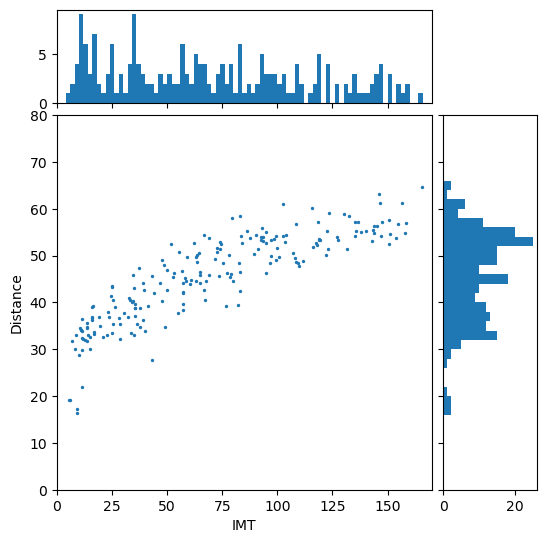

In [246]:
plot_ProjDistHist(soft_erl_dist_imt.IMT, soft_erl_dist_imt.Proj_Dist)

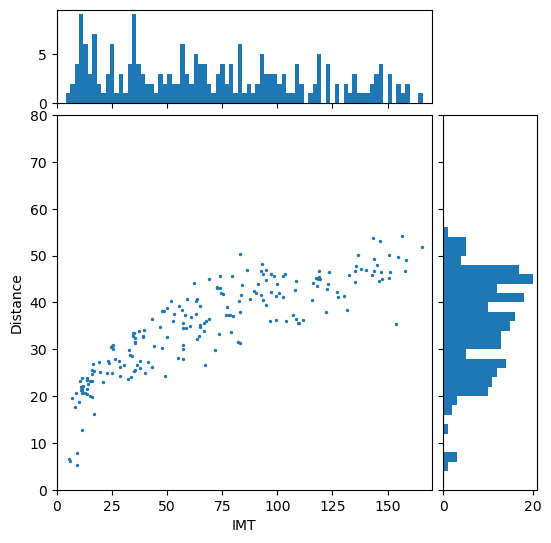

In [250]:
plot_ProjDistHist(soft_erl_dist_imt.IMT, soft_erl_dist_imt.Euc_Dist)

#### Soft, erlotinib (PCA)

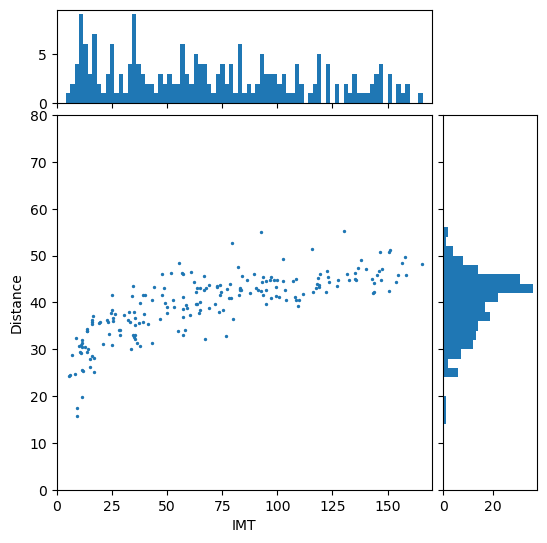

In [61]:
plot_ProjDistHist(soft_erl_dist_imt_pca.IMT, soft_erl_dist_imt_pca.Distance)

#### Soft, DMSO (UMAP)

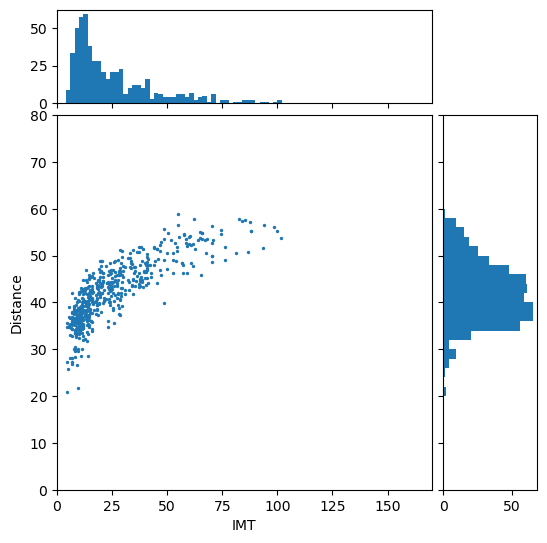

In [62]:
plot_ProjDistHist(soft_dmso_dist_imt.IMT, soft_dmso_dist_imt.Distance)

#### Soft, DMSO (PCA)

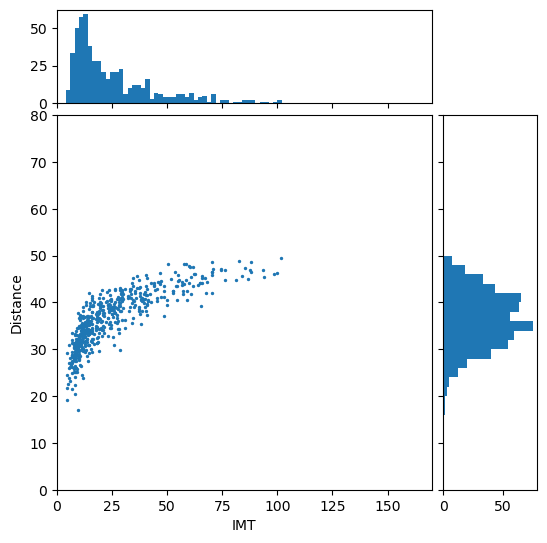

In [63]:
plot_ProjDistHist(soft_dmso_dist_imt_pca.IMT, soft_dmso_dist_imt_pca.Distance)

#### Int, ERL (UMAP)

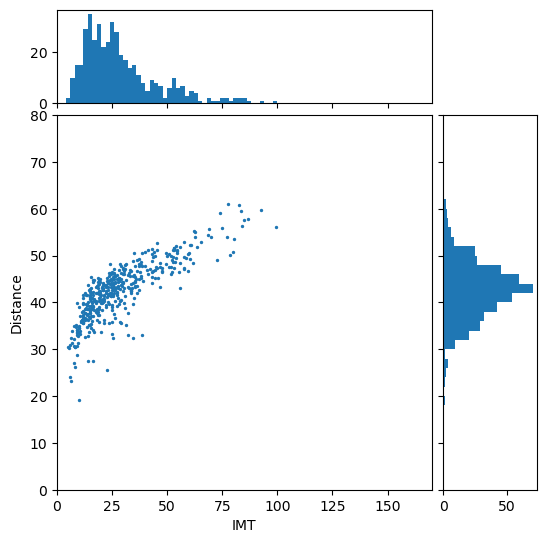

In [64]:
plot_ProjDistHist(int_erl_dist_imt.IMT, int_erl_dist_imt.Distance)

#### Int, ERL (PCA)

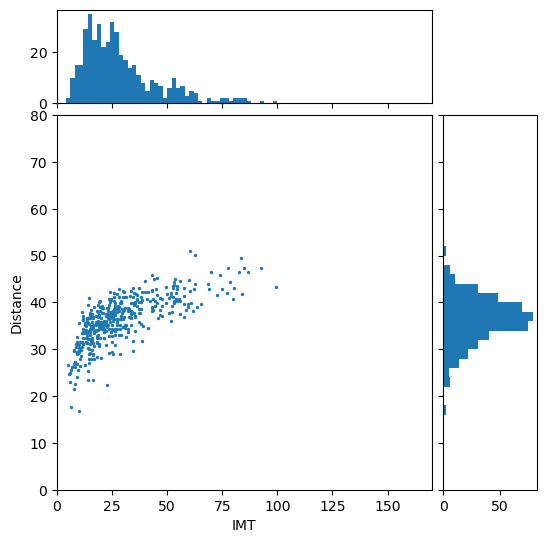

In [65]:
plot_ProjDistHist(int_erl_dist_imt_pca.IMT, int_erl_dist_imt_pca.Distance)

#### Int, DMSO (UMAP)

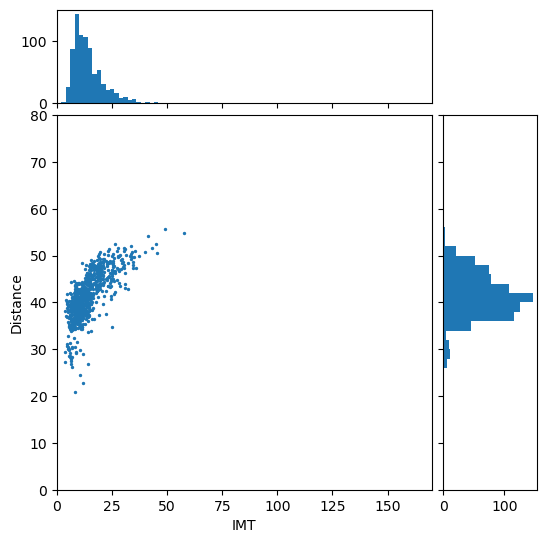

In [66]:
plot_ProjDistHist(int_dmso_dist_imt.IMT, int_dmso_dist_imt.Distance)

#### Int, DMSO (PCA)

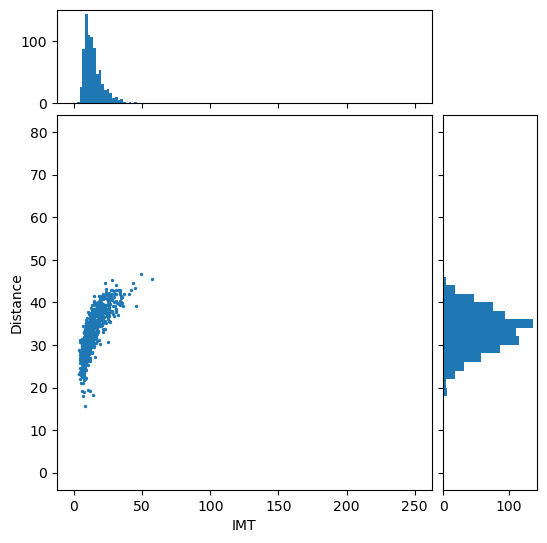

In [418]:
plot_ProjDistHist(int_dmso_dist_imt_pca.IMT, int_dmso_dist_imt_pca.Distance)

#### Stiff, ERL (UMAP)

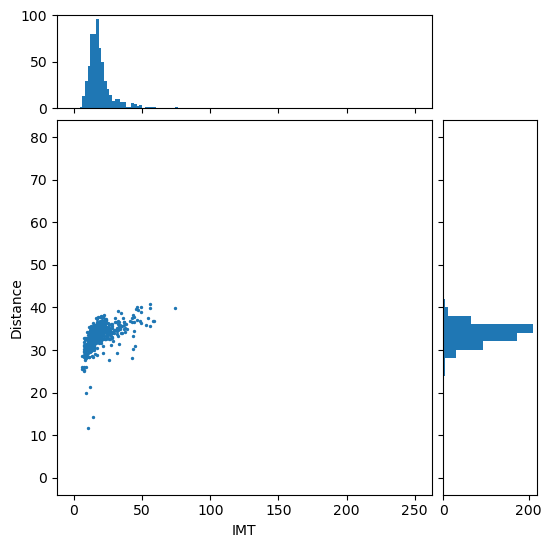

In [419]:
plot_ProjDistHist(stiff_erl_dist_imt.IMT, stiff_erl_dist_imt.Distance)

#### Stiff, ERL (PCA)

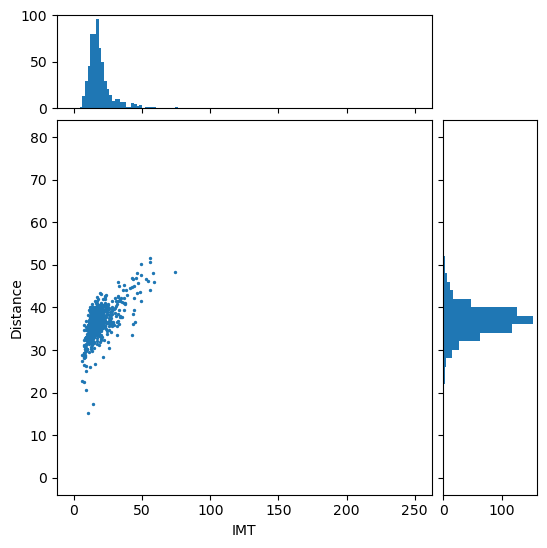

In [420]:
plot_ProjDistHist(stiff_erl_dist_imt_pca.IMT, stiff_erl_dist_imt_pca.Distance)

#### Stiff, DMSO (UMAP)

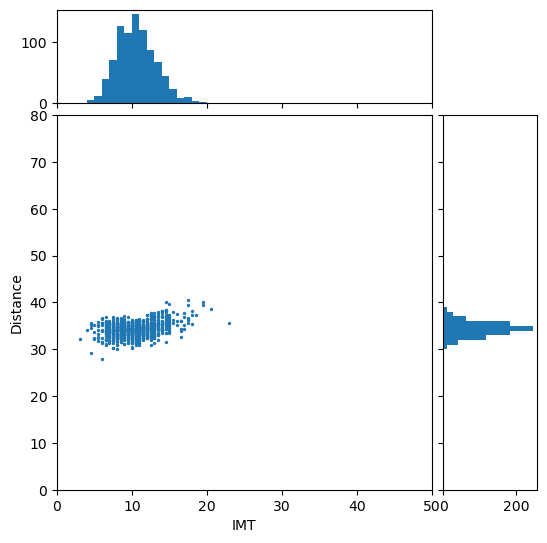

In [260]:
plot_ProjDistHist(stiff_dmso_dist_imt.IMT, stiff_dmso_dist_imt.Proj_Dist)

#### Stiff, DMSO (PCA)

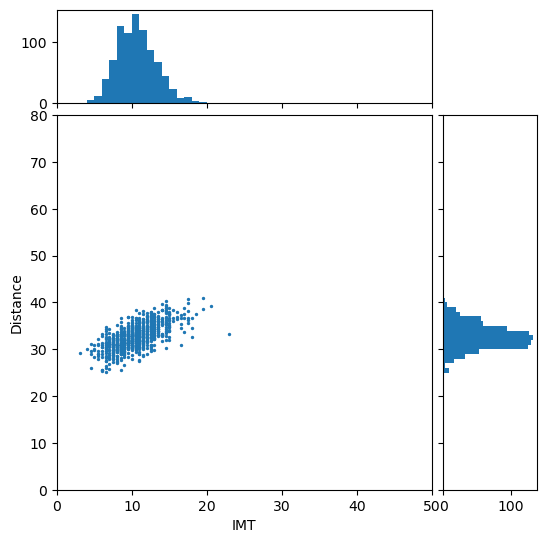

In [259]:
plot_ProjDistHist(stiff_dmso_dist_imt_pca.IMT, stiff_dmso_dist_imt_pca.Proj_Dist)

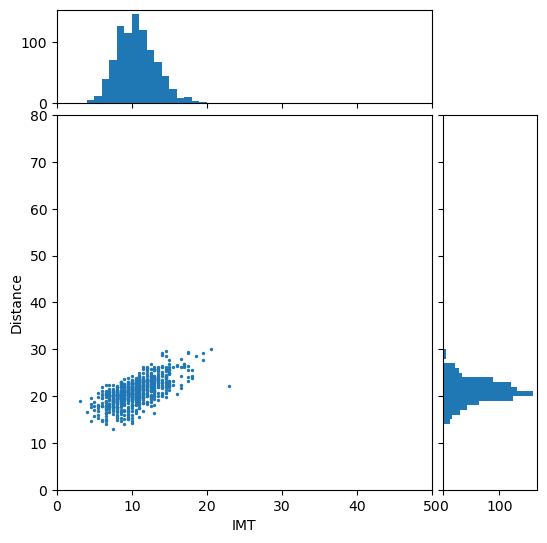

In [261]:
plot_ProjDistHist(stiff_dmso_dist_imt_pca.IMT, stiff_dmso_dist_imt_pca.Euc_Dist)

In [71]:
ode_proj = principalComponents_ode[3*trk_len_ode:3*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[3*trk_len_ode:3*trk_len_ode+200,:]
stoch_proj = pca_win_erl_int
stoch_wind = mit_win_erl_int
time_win = time_win_erl_int

In [73]:
def calc_distances(ode_proj, ode_wind, stoch_proj, stoch_wind, time_win):
    all_d_proj = []
    for row in range(len(stoch_proj)):
        difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
        min_d = min(difs)
        all_d_proj.append(min_d)
        if (row%10000) == 0:
            print(row)
    
    all_d = []
#     for n in time_win['div'].unique():
#         tmpDF = time_win.loc[time_win['div'] == n]
#         tmp = np.array(stoch_wind.iloc[tmpDF.iloc[0,3]:tmpDF.iloc[0,5],:])
#         tmp_umap = np.array(umapDF.iloc[tmpDF.index[0]:tmpDF.index[-1],:])
    for row in range(len(stoch_wind)):
        difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
        min_d = min(difs)
        all_d.append(min_d)
        if (row%10000) == 0:
            print(row)
        
    return all_d_proj, all_d

### Distance comparisons

#### Int, ERL

In [161]:
import multiprocess as mp
import time

In [162]:
ode_proj = principalComponents_ode[3*trk_len_ode:4*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[3*trk_len_ode:4*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[3*trk_len_ode:4*trk_len_ode+200,:]
stoch_proj = pca_win_erl_int
stoch_proj_umap = umap_win_erl_int
stoch_wind = mit_win_erl_int
time_win = time_win_erl_int

In [173]:
def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

In [174]:
def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

In [175]:
def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [166]:
test = calc_dis_proj(0)
test

0.9971884231213298

In [167]:
test1 = calc_dis_proj_umap(0)
test1

1.0539314

In [168]:
test2 = calc_dis_win(0)
test2

2.5798904654070287

In [92]:
stoch_wind.shape

(42340, 720)

In [85]:
rows = list(range(len(stoch_proj)))

In [86]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)
end = time.time()
print(end - start)

1227.3732357025146


In [132]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)
end = time.time()
print(end - start)

1024.4876391887665


In [98]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)

2062.5617463588715


In [438]:
len(all_d)

42340

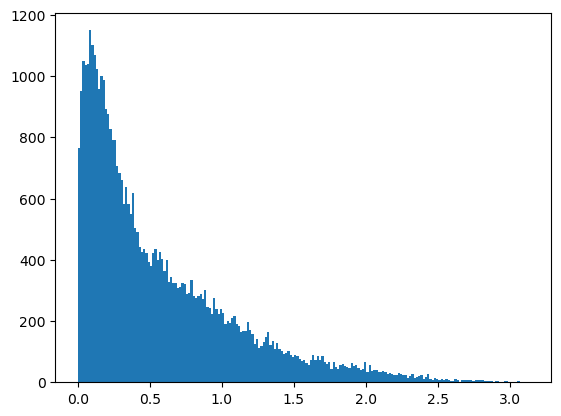

In [130]:
his1 = plt.hist(results_proj, bins=200)

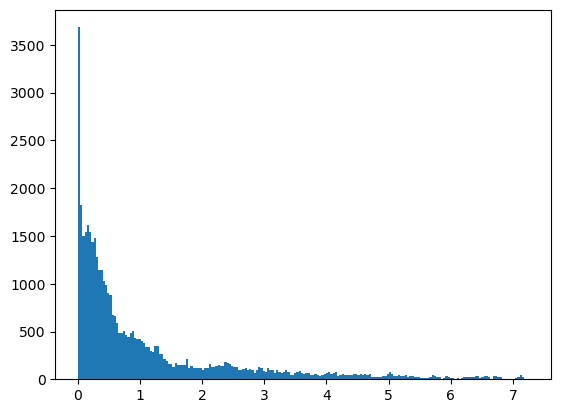

In [137]:
his2 = plt.hist(results_proj_umap, bins=200)

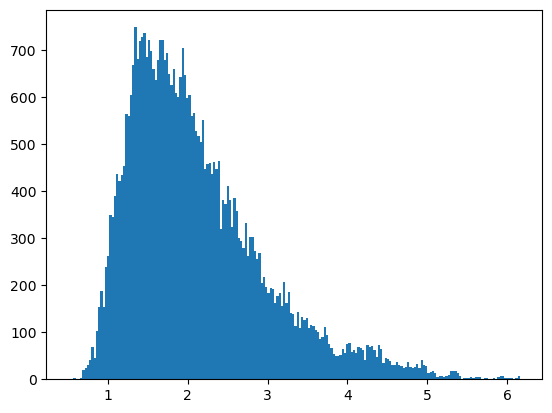

In [144]:
his3= plt.hist(results_wind, bins=200)

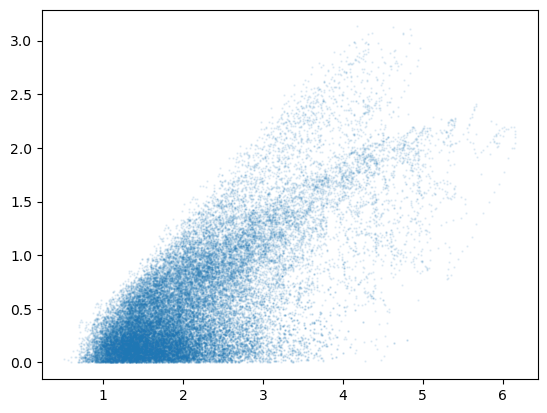

In [102]:
plt.scatter(results_wind[:], results_proj[:], s=0.5, alpha=0.1)

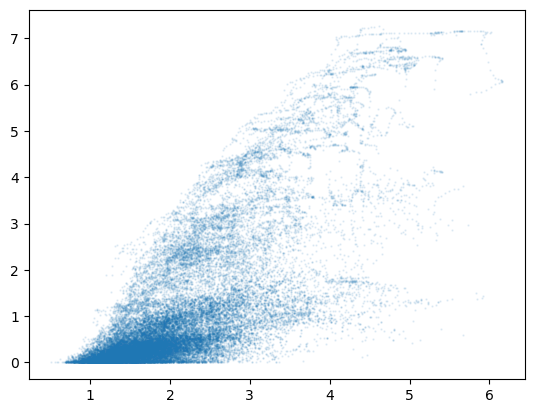

In [134]:
plt.scatter(results_wind[:], results_proj_umap[:], s=0.5, alpha=0.1)

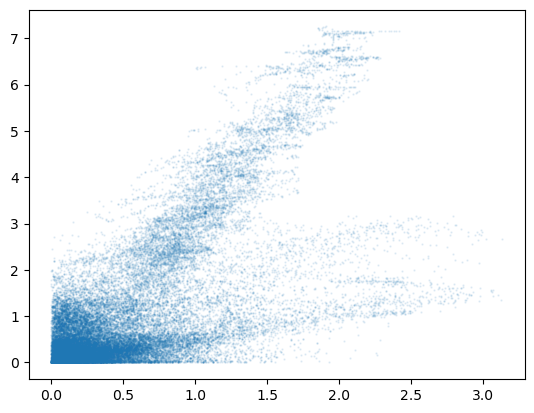

In [135]:
plt.scatter(results_proj[:], results_proj_umap[:], s=0.5, alpha=0.1)

Text(0.5, 1.0, 'UMAP ERL, Int.')

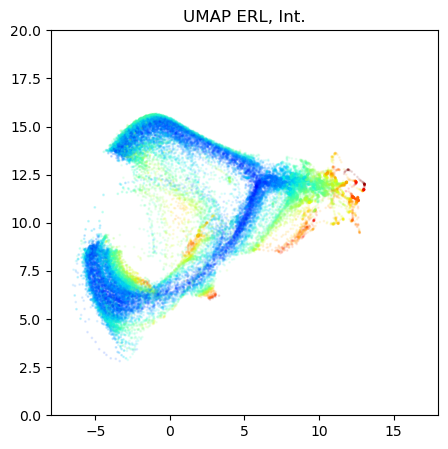

In [147]:
xmin, xmax = -8, 18
ymin, ymax = 0, 20


fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(umap_win_erl_int[0],umap_win_erl_int[1],c=results_wind,s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 6)
plt.title("UMAP ERL, Int.")

Text(0.5, 1.0, 'UMAP ERL, Int.')

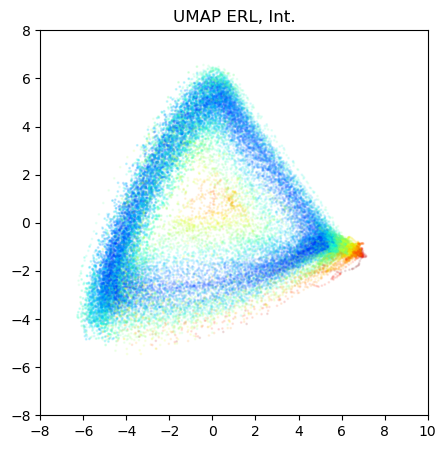

In [142]:
xmin, xmax = -8, 10
ymin, ymax = -8, 8

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(pca_win_erl_int[0],pca_win_erl_int[1],c=results_wind,s=1,cmap='jet',
           alpha=0.1)
plt.clim(0, 6)
plt.title("UMAP ERL, Int.")

In [189]:
ode_proj = principalComponents_ode[2*trk_len_ode:3*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[2*trk_len_ode:3*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[2*trk_len_ode:3*trk_len_ode+200,:]
stoch_proj = pca_win_dmso_int
stoch_proj_umap = umap_win_dmso_int
stoch_wind = mit_win_dmso_int
time_win = time_win_dmso_int
rows = list(range(len(stoch_proj)))

In [190]:
test = calc_dis_proj(0)
test

0.16934159712284863

In [191]:
test1 = calc_dis_proj_umap(0)
test1

0.023289312

In [192]:
test2 = calc_dis_win(0)
test2

1.196882368503437

In [193]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)
end = time.time()
print(end - start)

1253.8880531787872


In [194]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)
end = time.time()
print(end - start)

1317.61528134346


In [195]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)

2352.946933746338


### DMSO Soft

In [525]:
ode_proj = principalComponents_ode[0*trk_len_ode:0*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[0*trk_len_ode:0*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[0*trk_len_ode:0*trk_len_ode+200,:]
stoch_proj = pca_win_dmso_soft
stoch_proj_umap = umap_win_dmso_soft
stoch_wind = mit_win_dmso_soft
time_win = time_win_dmso_soft
rows = list(range(len(stoch_proj)))

In [526]:
def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [527]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)

with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)


163.98856019973755


In [528]:
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\pca_soft_dmso.csv", np.asarray(results_proj), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\umap_soft_dmso.csv", np.asarray(results_proj_umap), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\euc_soft_dmso.csv", np.asarray(results_wind), delimiter=",")

### ERL Soft

In [529]:
ode_proj = principalComponents_ode[1*trk_len_ode:1*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[1*trk_len_ode:1*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[1*trk_len_ode:1*trk_len_ode+200,:]
stoch_proj = pca_win_erl_soft
stoch_proj_umap = umap_win_erl_soft
stoch_wind = mit_win_erl_soft
time_win = time_win_erl_soft
rows = list(range(len(stoch_proj)))

In [530]:
def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [531]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)

with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)


135.7646141052246


In [532]:
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\pca_soft_erl.csv", np.asarray(results_proj), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\umap_soft_erl.csv", np.asarray(results_proj_umap), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\euc_soft_erl.csv", np.asarray(results_wind), delimiter=",")

In [533]:
### DMSO Int

ode_proj = principalComponents_ode[2*trk_len_ode:2*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[2*trk_len_ode:2*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[2*trk_len_ode:2*trk_len_ode+200,:]
stoch_proj = pca_win_dmso_int
stoch_proj_umap = umap_win_dmso_int
stoch_wind = mit_win_dmso_int
time_win = time_win_dmso_int
rows = list(range(len(stoch_proj)))

def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [534]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)

with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)

200.0922019481659


In [535]:
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\pca_int_dmso.csv", np.asarray(results_proj), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\umap_int_dmso.csv", np.asarray(results_proj_umap), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\euc_int_dmso.csv", np.asarray(results_wind), delimiter=",")

In [536]:
### ERL Int

ode_proj = principalComponents_ode[3*trk_len_ode:3*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[3*trk_len_ode:3*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[3*trk_len_ode:3*trk_len_ode+200,:]
stoch_proj = pca_win_erl_int
stoch_proj_umap = umap_win_erl_int
stoch_wind = mit_win_erl_int
time_win = time_win_erl_int
rows = list(range(len(stoch_proj)))

def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [537]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)

with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)

149.3276970386505


In [538]:
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\pca_int_erl.csv", np.asarray(results_proj), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\umap_int_erl.csv", np.asarray(results_proj_umap), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\euc_int_erl.csv", np.asarray(results_wind), delimiter=",")

In [539]:
### DMSO Stiff

ode_proj = principalComponents_ode[4*trk_len_ode:4*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[4*trk_len_ode:4*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[4*trk_len_ode:4*trk_len_ode+200,:]
stoch_proj = pca_win_dmso_stiff
stoch_proj_umap = umap_win_dmso_stiff
stoch_wind = mit_win_dmso_stiff
time_win = time_win_dmso_stiff
rows = list(range(len(stoch_proj)))

def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [540]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)

with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)

219.64323663711548


In [541]:
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\pca_stiff_dmso.csv", np.asarray(results_proj), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\umap_stiff_dmso.csv", np.asarray(results_proj_umap), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\euc_stiff_dmso.csv", np.asarray(results_wind), delimiter=",")

In [542]:
### ERL Stiff

ode_proj = principalComponents_ode[5*trk_len_ode:5*trk_len_ode+200,:]
ode_proj_umap = embedding_all_prot_ode[5*trk_len_ode:5*trk_len_ode+200,:]
ode_wind = all_prot_tmp_ode_ab[5*trk_len_ode:5*trk_len_ode+200,:]
stoch_proj = pca_win_erl_stiff
stoch_proj_umap = umap_win_erl_stiff
stoch_wind = mit_win_erl_stiff
time_win = time_win_erl_stiff
rows = list(range(len(stoch_proj)))

def calc_dis_proj(row, stoch_proj=stoch_proj, ode_proj=ode_proj, norm=norm):
    difs = [norm(stoch_proj.iloc[row].to_numpy() - ode_proj[n,:]) for n in range(len(ode_proj))]
    min_d = min(difs)
    return min_d

def calc_dis_proj_umap(row, stoch_proj_umap=stoch_proj_umap, ode_proj_umap=ode_proj_umap, norm=norm):
    difs = [norm(stoch_proj_umap.iloc[row].to_numpy() - ode_proj_umap[n,:]) for n in range(len(ode_proj_umap))]
    min_d = min(difs)
    return min_d

def calc_dis_win(row, stoch_wind=stoch_wind, ode_wind=ode_wind, norm=norm, np=np):
    difs = [norm(np.array(stoch_wind.iloc[row,:]) - ode_wind[n,:]) for n in range(len(ode_wind))]
    min_d = min(difs)
    return min_d

In [543]:
start = time.time()
with mp.Pool(processes = 15) as p:
    results_proj = p.map(calc_dis_proj, rows)

with mp.Pool(processes = 15) as p:
    results_proj_umap = p.map(calc_dis_proj_umap, rows)

with mp.Pool(processes = 15) as p:
    results_wind = p.map(calc_dis_win, rows)
end = time.time()
print(end - start)

167.0317680835724


In [544]:
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\pca_stiff_erl.csv", np.asarray(results_proj), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\umap_stiff_erl.csv", np.asarray(results_proj_umap), delimiter=",")
np.savetxt("C:\\Users\\olesk\\ECM_mod_output\\calc_dists\\euc_stiff_erl.csv", np.asarray(results_wind), delimiter=",")

Text(0.5, 1.0, 'PCA ERL, Soft')

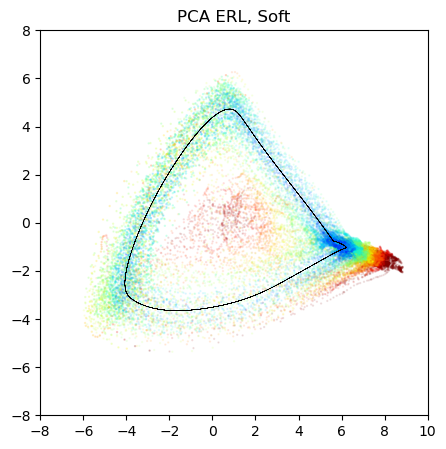

In [468]:
xmin, xmax = -8, 10
ymin, ymax = -8, 8


fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(pca_win_erl_soft[0],pca_win_erl_soft[1],c=arr1,s=0.5,cmap='jet',
           alpha=0.1)
plt.plot(principalComponents_ode[1*trk_len_ode:2*trk_len_ode,0], 
         principalComponents_ode[1*trk_len_ode:2*trk_len_ode,1], lw=0.05, alpha=1, color='black')
plt.clim(0, 5)
plt.title("PCA ERL, Soft")

Text(0.5, 1.0, 'PCA DMSO, Soft')

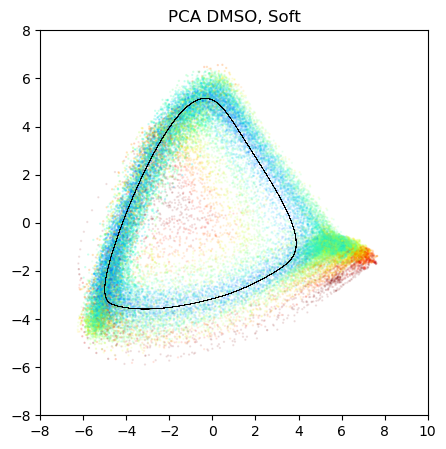

In [470]:
xmin, xmax = -8, 10
ymin, ymax = -8, 8

fig = plt.figure()
ax = fig.gca()
ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
fig.set_size_inches(5, 5)
plt.scatter(pca_win_dmso_soft[0],pca_win_dmso_soft[1],c=arr4,s=0.5,cmap='jet',
           alpha=0.1)
plt.plot(principalComponents_ode[0*trk_len_ode:1*trk_len_ode,0], 
         principalComponents_ode[0*trk_len_ode:1*trk_len_ode,1], lw=0.05, alpha=1, color='black')
plt.clim(0, 5)
#plt.colorbar()
plt.title("PCA DMSO, Soft")

In [556]:
def plotDistHist(data, color='black', linewidth=3, bw=0.02, lim=3, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', 
                         density=True, label=label)
    return his1

In [557]:
def plotDistHistCDF(data, color='black', linewidth=3, bw=0.02, lim=3, label='DistHist'):
    xbins = np.arange(0, lim + bw, bw)
    
    _, _, his1= plt.hist(data, bins=xbins, color=color, linewidth=linewidth, histtype=u'step', density=True, 
                         cumulative=True, label=label)
    return his1

In [563]:
DATADIR = "C:/Users/olesk/ECM_mod_output/calc_dists/"

filepaths = os.listdir(DATADIR)
filenames = [f for f in filepaths if re.match(r'^umap', f)]
filepaths = [Path(DATADIR, f) for f in filenames]
filepaths_s = [filepaths[2], filepaths[3], filepaths[0], filepaths[1], filepaths[4], filepaths[5]]
filepaths_s

[WindowsPath('C:/Users/olesk/ECM_mod_output/calc_dists/umap_soft_dmso.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/calc_dists/umap_soft_erl.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/calc_dists/umap_int_dmso.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/calc_dists/umap_int_erl.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/calc_dists/umap_stiff_dmso.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/calc_dists/umap_stiff_erl.csv')]

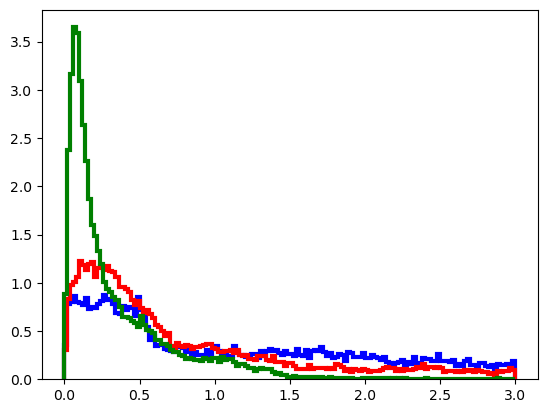

In [564]:
arr1 = np.loadtxt(filepaths_s[1], delimiter=",")
arr2 = np.loadtxt(filepaths_s[3], delimiter=",")
arr3 = np.loadtxt(filepaths_s[5], delimiter=",")

his1= plotDistHist(arr1, color='blue')
his2= plotDistHist(arr2, color='red')
his3= plotDistHist(arr3, color='green')

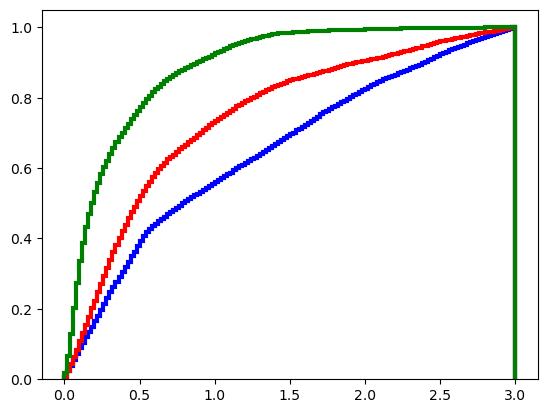

In [565]:
his1= plotDistHistCDF(arr1, color='blue')
his2= plotDistHistCDF(arr2, color='red')
his3= plotDistHistCDF(arr3, color='green')

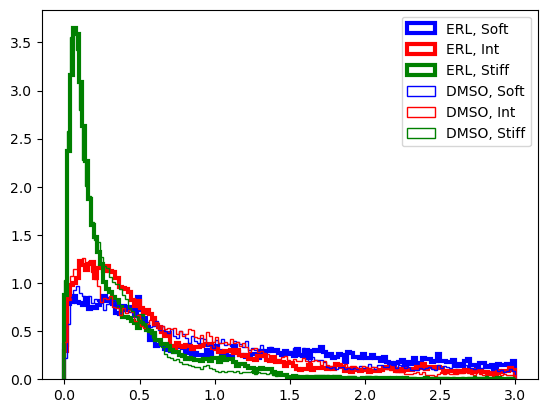

In [566]:
arr4 = np.loadtxt(filepaths_s[0], delimiter=",")
arr5 = np.loadtxt(filepaths_s[2], delimiter=",")
arr6 = np.loadtxt(filepaths_s[4], delimiter=",")

his1= plotDistHist(arr1, color='blue', label='ERL, Soft')
his2= plotDistHist(arr2, color='red', label='ERL, Int')
his3= plotDistHist(arr3, color='green', label='ERL, Stiff')
his4= plotDistHist(arr4, color='blue', linewidth=1, label='DMSO, Soft')
his5= plotDistHist(arr5, color='red', linewidth=1, label='DMSO, Int')
his6= plotDistHist(arr6, color='green', linewidth=1, label='DMSO, Stiff')

plt.legend()

In [553]:
sum(arr4)

133238.0907846597

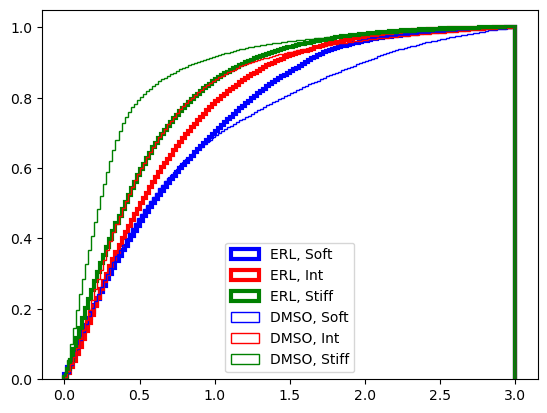

In [561]:
his1= plotDistHistCDF(arr1, color='blue', label='ERL, Soft')
his2= plotDistHistCDF(arr2, color='red', label='ERL, Int')
his3= plotDistHistCDF(arr3, color='green', label='ERL, Stiff')
his4= plotDistHistCDF(arr4, color='blue', linewidth=1, label='DMSO, Soft')
his5= plotDistHistCDF(arr5, color='red', linewidth=1, label='DMSO, Int')
his6= plotDistHistCDF(arr6, color='green', linewidth=1, label='DMSO, Stiff')

plt.legend()

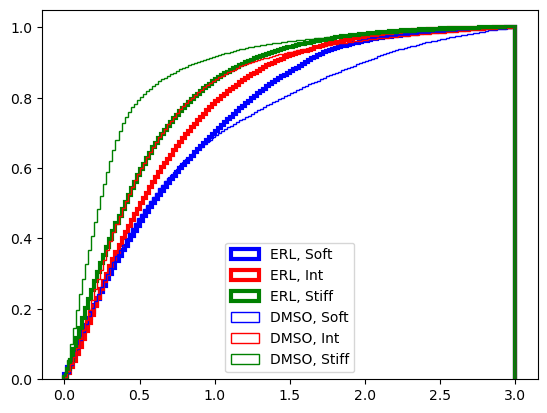

In [562]:
his1= plotDistHistCDF(arr1, color='blue', label='ERL, Soft')
his2= plotDistHistCDF(arr2, color='red', label='ERL, Int')
his3= plotDistHistCDF(arr3, color='green', label='ERL, Stiff')
his4= plotDistHistCDF(arr4, color='blue', linewidth=1, label='DMSO, Soft')
his5= plotDistHistCDF(arr5, color='red', linewidth=1, label='DMSO, Int')
his6= plotDistHistCDF(arr6, color='green', linewidth=1, label='DMSO, Stiff')

plt.legend()

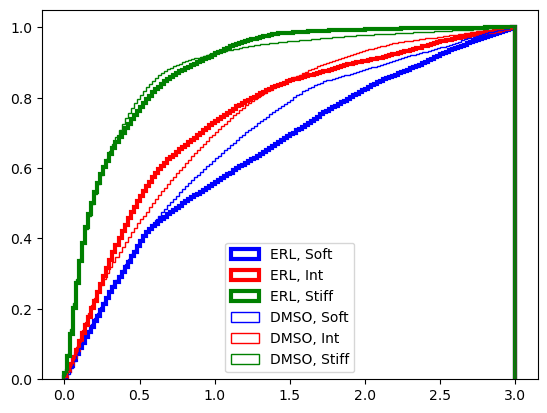

In [567]:
his1= plotDistHistCDF(arr1, color='blue', label='ERL, Soft')
his2= plotDistHistCDF(arr2, color='red', label='ERL, Int')
his3= plotDistHistCDF(arr3, color='green', label='ERL, Stiff')
his4= plotDistHistCDF(arr4, color='blue', linewidth=1, label='DMSO, Soft')
his5= plotDistHistCDF(arr5, color='red', linewidth=1, label='DMSO, Int')
his6= plotDistHistCDF(arr6, color='green', linewidth=1, label='DMSO, Stiff')

plt.legend()